# 1. Importations

## 1.1 Importations des librairies

In [1]:
import os

In [2]:
os.environ["KERAS_BACKEND"]="torch"
import gc
import json
import time
import keras
import torch
import shutil
import collections
import numpy as np
from PIL import Image
from pathlib import Path
from tqdm.auto import tqdm
from keras import layers, ops
import matplotlib.pyplot as plt
from sklearn.utils import shuffle
from nltk.translate.bleu_score import SmoothingFunction, sentence_bleu
from keras.applications.inception_v3 import InceptionV3, preprocess_input
import tensorflow as tf

I0000 00:00:1792679868.425169  166462 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792679868.654888  166462 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792679869.969468  166462 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Comme pour les livrables précédents on utilisera pytorch en backend pour pouvoir utilisé le GPU avec Keras malgré qu'on soit sur windows

In [3]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Backend Keras : {keras.backend.backend()}")
print(f"Device d'entraînement : {DEVICE}")

Backend Keras : torch
Device d'entraînement : cuda


## 1.2 Chemins

In [4]:
PROJECT_DIR = os.path.abspath(os.getcwd())
MODELS_DIR = os.path.join(PROJECT_DIR, "models")
CLASSIFIER_WEIGHTS = os.path.join(MODELS_DIR, "model_full.weights.h5")
DENOISER_MODEL = os.path.join(MODELS_DIR, "unet_denoiser_livrable2.keras")
DATASETS_DIR = os.path.join(PROJECT_DIR, "datasets", "Livrable 3")
COCO_DIR = os.path.join(DATASETS_DIR, "train2014")
PHOTOS_DIR = os.path.join(DATASETS_DIR, "photos")
DENOISED_DIR = os.path.join(DATASETS_DIR, "denoised_images")
ANNOTATIONS_DIR = os.path.join(DATASETS_DIR, "annotations")
ANNOTATION_FILE = os.path.join(ANNOTATIONS_DIR, "captions_train2014.json")

## 2. Workflow de prétraitement des données

### Etape 1 : classification Photo / Non-photo
Le modèle du livrable 1 reconnaît cinq classes : Painting, Photo, Schematics, Sketch et Text. Il faut donc garder ses cinq sorties : l’étape est dite binaire parce qu’on transforme ensuite sa prédiction en deux groupes, Photo et Non-photo.

Pour chaque image, le code :

la redimensionne en 128 × 128 ;
la passe au modèle, qui divise ses pixels par 255 grâce à sa couche Rescaling ;
récupère la probabilité associée à Photo ;
la compare au seuil 0,2301, défini dans le livrable 1.
Si la probabilité atteint le seuil, l’image est considérée comme une photo. Sinon, elle reste dans son dossier d’origine. Le code déplace les photos retenues dans datasets/photos — il ne les copie pas — mais ne déplace pas et ne supprime pas les autres images.

In [5]:
CLASS_NAMES = ["Painting", "Photo", "Schematics", "Sketch", "Text"]
NUM_CLASSES = len(CLASS_NAMES)
PHOTO_CLASS_INDEX = CLASS_NAMES.index("Photo")
THRESHOLD = 0.2301

In [6]:
def load_classifier_model():
    model = keras.models.load_model(CLASSIFIER_WEIGHTS, compile=False)
    return model

def load_image_as_array(path, target_size=(128, 128)):
    with Image.open(path) as image:
        image = image.convert("RGB").resize(target_size)
        return np.asarray(image, dtype=np.float32)

def classify_images(image_dir: str | Path,classifier: keras.models.Model):
    results = []
    image_dir = Path(image_dir)

    for image_file in tqdm(image_dir.iterdir()):
        image_array = load_image_as_array(str(image_file))
        image_array = np.expand_dims(image_array, axis=0)

        probabilities = classifier.predict(image_array,verbose=0)
        proba_photo = float(probabilities[0][PHOTO_CLASS_INDEX])

        results.append((str(image_file),proba_photo,proba_photo >= THRESHOLD))

    return results

def move_photos_to_folder(classification_results, dest_dir=PHOTOS_DIR):
    os.makedirs(dest_dir, exist_ok=True)
    moved = []
    for path, _, is_photo in classification_results:
        if is_photo:
            if os.path.abspath(os.path.dirname(path)) != os.path.abspath(dest_dir):
                filename = os.path.basename(path)
                dest_path = os.path.join(dest_dir, filename)
                if os.path.exists(dest_path):
                    base, extension = os.path.splitext(filename)
                    suffix = 1
                    while os.path.exists(dest_path):
                        dest_path = os.path.join(dest_dir, f"{base}_{suffix}{extension}")
                        suffix += 1
                shutil.move(path, dest_path)
                path = dest_path
            moved.append(path)
    return moved

### Etape 2 : débruitage avec le U-Net du livrable 2
Chaque photo retenue est chargée en RGB, redimensionnée en 299 × 299 et convertie en valeurs entre 0 et 1. Le U-Net du livrable 2 est ensuite appliqué à l’image, et le résultat est sauvegardé dans datasets/denoised_images.

Le U-Net effectue des opérations de pooling qui nécessitent des dimensions compatibles avec des réductions par deux. Le code complète donc temporairement les dimensions de 299 à 300, puis recadre le résultat à 299 × 299 avant de le sauvegarder.

In [7]:
def load_denoiser_model():
    denoiser = keras.models.load_model(DENOISER_MODEL, compile=False)
    return denoiser

def load_image_for_denoiser(path, target_size=(299, 299)):
    with Image.open(path) as image:
        image = image.convert("RGB").resize(target_size)
        return np.asarray(image, dtype=np.float32) / 255.0

def denoise_images(image_paths, denoiser, output_dir=DENOISED_DIR):
    os.makedirs(output_dir, exist_ok=True)

    for path in tqdm(image_paths):
        arr = load_image_for_denoiser(path)
        height, width = arr.shape[:2]
        pad_height = (-height) % 4
        pad_width = (-width) % 4
        padded = np.pad(arr, ((0, pad_height), (0, pad_width), (0, 0)), mode="edge")
        batch = np.expand_dims(padded, axis=0)
        denoised = keras.ops.convert_to_numpy(denoiser(batch, training=False))[0]
        denoised = denoised[:height, :width, :]
        denoised = np.clip(denoised, 0.0, 1.0)

        denoised_img = Image.fromarray(np.rint(denoised * 255).astype("uint8"))
        filename = os.path.basename(path)
        out_path = os.path.join(output_dir, filename)
        denoised_img.save(out_path)
        gc.collect()
        torch.cuda.empty_cache()


### Etape 3: Extraction des features avec Inception V3

Après avoir débruité chaque image du dataset on extrait les caractéristiques en utilisant le modèle InceptionV3

In [8]:
def build_inception_feature_extractor():
    image_model = InceptionV3(weights="imagenet", include_top=False)
    new_input = keras.Input(shape=(299, 299, 3))
    return keras.Model(new_input, image_model(new_input))


def load_image_for_inception(path, target_size=(299, 299)):
    with Image.open(path) as image:
        image = image.convert("RGB").resize(target_size)
        image = np.asarray(image, dtype="float32")
    return preprocess_input(image), path


def extract_and_save_inception_features(img_name_vector, feature_extractor, batch_size=8):
    image_paths = sorted(set(img_name_vector))
    for start in tqdm(range(0, len(image_paths), batch_size)):
        paths = image_paths[start:start + batch_size]
        images = np.stack([load_image_for_inception(path)[0] for path in paths])
        batch_features = feature_extractor(images, training=False)
        batch_features = ops.reshape(
            batch_features,
            (batch_features.shape[0], -1, batch_features.shape[-1])
        )
        for feature, path in zip(ops.convert_to_numpy(batch_features), paths):
            np.save(path, feature)

### Etape 4: Création du dataset

#### Prétaitement des annotations

In [9]:
def create_captions_and_path_vectors(annotation_file, already_done=False):
    image_path_to_caption = collections.defaultdict(list)
    train_captions = []
    img_name_vector = []
    mark_start, mark_end = '<start> ', ' <end>'
    end_path = '.npy' if already_done else ''

    with open(annotation_file, 'r', encoding='utf-8') as f:
        annotations = json.load(f)

    for val in annotations['annotations']:
        caption = mark_start + val['caption'].strip() + mark_end
        image_path = os.path.join(
            DENOISED_DIR,
            'COCO_train2014_' + '%012d.jpg' % val['image_id'] + end_path
        )
        if os.path.isfile(image_path):
            image_path_to_caption[image_path].append(caption)

    for image_path, caption_list in image_path_to_caption.items():
        train_captions.extend(caption_list)
        img_name_vector.extend([image_path] * len(caption_list))

    return img_name_vector, train_captions

def calc_max_length(tensor):
    return max(len(t) for t in tensor)

def annotation_preprocessing(train_captions, top_k=5000):
    tokenizer = tf.keras.preprocessing.text.Tokenizer(num_words=top_k,
                                                    oov_token="<unk>",
                                                    filters='!"#$%&()*+.,-/:;=?@[\\]^_`{|}~')

    tokenizer.fit_on_texts(train_captions)
    tokenizer.word_index['<pad>'] = 0
    tokenizer.index_word[0] = '<pad>'
    train_seqs = tokenizer.texts_to_sequences(train_captions)
    cap_vector = keras.preprocessing.sequence.pad_sequences(train_seqs, padding='post')
    max_length = calc_max_length(train_seqs)

    return cap_vector, max_length, tokenizer

#### Création du dataset à partir des annotations et des images prétraitées

In [10]:
class FeatureCaptionDataset(torch.utils.data.Dataset):
    def __init__(self, image_paths, captions):
        self.image_paths = image_paths
        self.captions = captions

    def __len__(self):
        return len(self.captions)

    def __getitem__(self, index):
        return np.load(self.image_paths[index]).astype("float32"), self.captions[index]


def data_splitting(img_name_vector, cap_vector, batch_size):
    img_to_cap_vector = collections.defaultdict(list)
    for img, cap in zip(img_name_vector, cap_vector):
        img_to_cap_vector[img].append(cap)

    img_keys_shuffled = shuffle(list(img_to_cap_vector.keys()), random_state=42)
    slice_index_t, slice_index_v = int(len(img_keys_shuffled) * 0.02), int(len(img_keys_shuffled) * 0.03)
     #TODO juste pour ne pas prendre tout le dataset ici on ne prend que 20% train et 10% val
    train_keys = img_keys_shuffled[:slice_index_t]
    val_keys = img_keys_shuffled[slice_index_t:slice_index_v]
    train_paths = [path for path in train_keys for _ in img_to_cap_vector[path]]
    train_caps = [cap for path in train_keys for cap in img_to_cap_vector[path]]
    val_paths = [path for path in val_keys for _ in img_to_cap_vector[path]]
    val_caps = [cap for path in val_keys for cap in img_to_cap_vector[path]]

    # Les features sont stockées sous la forme image.jpg.npy dans DENOISED_DIR,
    # mais l'évaluation doit recevoir les images .jpg présentes dans PHOTOS_DIR.
    img_name_val = [
        os.path.join(PHOTOS_DIR, Path(path).stem)
        for path in val_keys
        for _ in img_to_cap_vector[path]
    ]
    cap_val = [
        cap
        for path in val_keys
        for cap in img_to_cap_vector[path]
    ]

    dataset = FeatureCaptionDataset(train_paths, train_caps)
    train_loader = torch.utils.data.DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=True,
        drop_last=False,
        pin_memory=DEVICE.type == "cuda",
    )

    validation_dataset = FeatureCaptionDataset(val_paths, val_caps)
    validation_loader = torch.utils.data.DataLoader(
        validation_dataset,
        batch_size=batch_size,
        shuffle=False,
        drop_last=False,
        pin_memory=DEVICE.type == "cuda",
    )

    return train_loader, validation_loader, img_name_val, cap_val

### Exécution du workflow

In [11]:
def run_extraction_workflow():
    classifier = load_classifier_model()
    classification_results = classify_images(COCO_DIR, classifier)
    photos_moved = move_photos_to_folder(classification_results)
    print(f"{len(photos_moved)} photos déplacées dans {PHOTOS_DIR}.")

    print("2. Débruitage")
    denoiser_model = load_denoiser_model()
    denoise_images(photos_moved, denoiser_model)

    print("3. Chargement des données et prétraitement")
    img_name_vector, _ = create_captions_and_path_vectors(annotation_file=ANNOTATION_FILE)

    print("4. Extraction des caractéristiques avec InceptionV3")
    feature_extractor = build_inception_feature_extractor()
    extract_and_save_inception_features(img_name_vector, feature_extractor)
    print(f"Extraction terminée dans : {DENOISED_DIR}")

# La création du DataLoader est volontairement exclue de cette cellule.

Le workflow a déjà été exécuté en local donc il n'y aura pas de retour dans cette cellule

### Création du dataset

In [12]:
def create_dataset():
    img_name_vector, train_captions = create_captions_and_path_vectors(ANNOTATION_FILE, already_done=True)

    cap_vector, max_length, tokenizer = annotation_preprocessing(train_captions)

    dataset, validation_loader, img_name_val, cap_val = data_splitting(
        img_name_vector, cap_vector, BATCH_SIZE
    )

    return dataset, validation_loader, tokenizer, max_length, img_name_val, cap_val


# Étape 6 : comparaison GRU / LSTM avec un pipeline commun

Les deux modèles utilisent :

- le même `CNN_Encoder` ;
- la même attention de Bahdanau ;
- le même dataset d'entraînement et de validation ;
- les mêmes fonctions génériques d'entraînement et d'évaluation.

Seule la cellule récurrente du décodeur varie : `GRU` ou `LSTM`.

## 6.1 – Hyperparamètres communs

In [13]:
BATCH_SIZE = 32
EMBEDDING_DIM = 256
UNITS = 512
VOCAB_SIZE = 5001
EPOCHS = 1
LEARNING_RATE = 5e-5
DROPOUT = 0.3
L1 = 0.0                # elastic net désactivé par défaut
L2 = 0.0
LOG_EVERY = 10
ATTENTION_FEATURES_SHAPE = 64

## 6.2 – Encodeur et attention partagés

In [14]:
class CNN_Encoder(keras.Model):
    def __init__(self, embedding_dim, regularizer=None):
        super().__init__()
        self.fc = layers.Dense(embedding_dim, kernel_regularizer=regularizer)

    def call(self, features):
        return ops.relu(self.fc(features))


class BahdanauAttention(layers.Layer):
    def __init__(self, units):
        super().__init__()
        self.W_features = layers.Dense(units)
        self.W_hidden = layers.Dense(units)
        self.V = layers.Dense(1)

    def call(self, features, hidden):
        hidden_expanded = ops.expand_dims(hidden, axis=1)
        scores = self.V(
            ops.tanh(
                self.W_features(features)
                + self.W_hidden(hidden_expanded)
            )
        )
        weights = ops.softmax(scores, axis=1)
        context = ops.sum(weights * features, axis=1)
        return context, weights

## 6.3 – Décodeur commun GRU / LSTM

In [15]:
class AttentionDecoder(keras.Model):
    def __init__(self, embedding_dim, units, vocab_size, rnn_type,
                 dropout=DROPOUT, regularizer=None):
        super().__init__()
        if rnn_type not in ("gru", "lstm"):
            raise ValueError("rnn_type doit être 'gru' ou 'lstm'.")
        self.rnn_type = rnn_type
        self.units = units
        self.embedding = layers.Embedding(vocab_size, embedding_dim)
        self.attention = BahdanauAttention(units)
        if rnn_type == "gru":
            self.rnn = layers.GRU(
                units,
                return_sequences=True,
                return_state=True,
                dropout=dropout,
                recurrent_initializer="glorot_uniform",
            )
        else:
            self.rnn = layers.LSTM(
                units,
                return_sequences=True,
                return_state=True,
                dropout=dropout,
                recurrent_initializer="glorot_uniform",
            )
        # Elastic net (L1 + L2) sur les couches denses, comme dans le livrable 1
        self.fc1 = layers.Dense(units, kernel_regularizer=regularizer)
        self.fc2 = layers.Dense(vocab_size, kernel_regularizer=regularizer)

    def call(self, token, features, state, training=False):
        hidden = state[0] if self.rnn_type == "lstm" else state
        context, attention_weights = self.attention(features, hidden)
        embedded = self.embedding(token)
        recurrent_input = ops.concatenate(
            [ops.expand_dims(context, axis=1), embedded], axis=-1
        )
        if self.rnn_type == "gru":
            output, next_state = self.rnn(
                recurrent_input, initial_state=state, training=training
            )
        else:
            output, next_hidden, next_cell = self.rnn(
                recurrent_input, initial_state=state, training=training
            )
            next_state = (next_hidden, next_cell)
        logits = ops.squeeze(self.fc2(self.fc1(output)), axis=1)
        return logits, next_state, attention_weights

    def reset_state(self, batch_size):
        hidden = ops.zeros((batch_size, self.units))
        if self.rnn_type == "gru":
            return hidden
        return hidden, ops.zeros((batch_size, self.units))

## 6.4 – Dataset commun et instanciation des modèles

In [16]:
dataset, validation_loader, tokenizer, max_length, img_name_val, cap_val = create_dataset()


In [17]:
dummy_token = torch.zeros((1, 1), dtype=torch.int64, device=DEVICE)
dummy_features = torch.zeros((1, 64, 2048), device=DEVICE)

#gru
gru_encoder = CNN_Encoder(EMBEDDING_DIM)
gru_decoder = AttentionDecoder(
    EMBEDDING_DIM, UNITS, VOCAB_SIZE, rnn_type="gru"
)
gru_optimizer = keras.optimizers.Adam(learning_rate=LEARNING_RATE)
gru_encoded_features = gru_encoder(dummy_features)
gru_decoder(
    dummy_token, gru_encoded_features, gru_decoder.reset_state(1), training=False
)

#lstm
# lstm_encoder = CNN_Encoder(EMBEDDING_DIM)
# lstm_decoder = AttentionDecoder(
#     EMBEDDING_DIM, UNITS, VOCAB_SIZE, rnn_type="lstm"
# )
# lstm_optimizer = keras.optimizers.Adam(learning_rate=LEARNING_RATE)
# lstm_encoded_features = lstm_encoder(dummy_features)
# lstm_decoder(
#     dummy_token, lstm_encoded_features, lstm_decoder.reset_state(1), training=False
# )

/home/jxc/.venvs/data/lib/python3.12/site-packages/keras/src/backend/torch/rnn.py:887: UserWarning: RNN module weights are not part of single contiguous chunk of memory. This means they need to be compacted at every call, possibly greatly increasing memory usage. To compact weights again call flatten_parameters(). (Triggered internally at /pytorch/aten/src/ATen/native/cudnn/RNN.cpp:1479.)
  outputs, h_n = torch._VF.gru(


(tensor([[-0.0031,  0.0003, -0.0036,  ..., -0.0010,  0.0014,  0.0051]],
        device='cuda:0', grad_fn=<SqueezeBackward1>),
 tensor([[ 5.3088e-03, -1.6325e-02, -2.6697e-04, -4.1960e-03, -1.9451e-03,
           1.2256e-02,  1.1175e-02, -1.4458e-03,  1.1708e-02, -7.6618e-03,
           1.3543e-03, -1.7731e-02, -6.0328e-04,  2.2796e-03,  1.4117e-02,
          -9.3862e-03, -6.8544e-03,  7.2235e-04,  7.3917e-03, -5.9322e-03,
           2.1927e-03, -2.2174e-03, -4.4698e-03, -6.8448e-04,  3.8475e-03,
          -8.1162e-04, -1.0769e-03, -2.3917e-03, -3.1450e-03,  3.5845e-03,
          -7.2164e-03, -1.0963e-02, -6.4731e-05, -3.7342e-03, -6.2852e-03,
           2.5354e-03,  1.2620e-02, -2.1103e-03,  8.9827e-03,  1.6858e-02,
           1.2800e-02, -1.6265e-03,  7.9880e-03,  6.1967e-03,  6.9949e-03,
           1.7165e-02,  1.0627e-02, -1.5365e-02, -3.0396e-03, -7.4867e-03,
          -1.0936e-03, -3.1818e-03, -2.2498e-04, -2.8085e-03, -5.9020e-03,
           1.8443e-03, -1.9990e-03,  5.6081e-04, 

## 6.5 – Fonctions communes d'entraînement et de validation

In [18]:
loss_object = keras.losses.SparseCategoricalCrossentropy(
    from_logits=True, reduction="none"
)


def masked_loss(real, predictions):
    mask = real != 0
    losses = loss_object(real, predictions)
    return (losses * ops.cast(mask, losses.dtype)).sum(), mask.sum()


def train_step(encoder, decoder, optimizer, img_tensor, target):
    images = torch.as_tensor(img_tensor, dtype=torch.float32, device=DEVICE)
    target = torch.as_tensor(target, dtype=torch.int64, device=DEVICE)
    batch_size = target.shape[0]
    state = decoder.reset_state(batch_size)
    start_token = tokenizer.word_index["<start>"]
    decoder_input = torch.full(
        (batch_size, 1), start_token, dtype=torch.int64, device=DEVICE
    )
    features = encoder(images)
    total_loss = torch.zeros((), dtype=torch.float32, device=DEVICE)
    total_tokens = torch.zeros((), dtype=torch.float32, device=DEVICE)

    for index in range(1, target.shape[1]):
        predictions, state, _ = decoder(
            decoder_input, features, state, training=True
        )
        step_loss, _ = masked_loss(target[:, index], predictions)
        total_loss = total_loss + step_loss
        total_tokens = total_tokens + (target[:, index] != 0).sum()
        decoder_input = target[:, index:index + 1]

    # Pénalité elastic net : fit() l'ajoute tout seul, pas une boucle écrite à la main.
    # total_loss est une somme sur les tokens, on multiplie donc la pénalité par leur
    # nombre pour garder le même rapport perte / pénalité qu'avec une perte moyenne.
    regularization_losses = encoder.losses + decoder.losses
    objective = total_loss
    if regularization_losses:
        objective = total_loss + sum(regularization_losses) * total_tokens

    variables = encoder.trainable_variables + decoder.trainable_variables
    gradients = torch.autograd.grad(
        objective,
        [variable.value for variable in variables],
        allow_unused=False,
    )
    optimizer.apply_gradients(zip(gradients, variables))
    return (total_loss / ops.maximum(total_tokens, 1.0)).detach()


def validation_step(encoder, decoder, img_tensor, target):
    images = torch.as_tensor(img_tensor, dtype=torch.float32, device=DEVICE)
    target = torch.as_tensor(target, dtype=torch.int64, device=DEVICE)
    batch_size = target.shape[0]
    state = decoder.reset_state(batch_size)
    start_token = tokenizer.word_index["<start>"]
    decoder_input = torch.full(
        (batch_size, 1), start_token, dtype=torch.int64, device=DEVICE
    )
    features = encoder(images)
    total_loss = torch.zeros((), dtype=torch.float32, device=DEVICE)
    total_tokens = torch.zeros((), dtype=torch.float32, device=DEVICE)
    correct_count = 0

    with torch.no_grad():
        for index in range(1, target.shape[1]):
            predictions, state, _ = decoder(
                decoder_input, features, state, training=False
            )
            step_loss, step_tokens = masked_loss(
                target[:, index], predictions
            )
            total_loss = total_loss + step_loss
            total_tokens = total_tokens + step_tokens
            valid_predictions = target[:, index] != 0
            correct_predictions = (
                torch.argmax(predictions, dim=-1) == target[:, index]
            )
            correct_count += int(
                (correct_predictions & valid_predictions).sum().item()
            )
            decoder_input = target[:, index:index + 1]
    return total_loss.detach(), total_tokens.detach(), correct_count

## 6.6 – BLEU et évaluation autoregressive communes

In [19]:
def bleu_score(encoder, decoder, img_tensor, target):
    images = torch.as_tensor(img_tensor, dtype=torch.float32, device=DEVICE)
    target = torch.as_tensor(target, dtype=torch.int64, device=DEVICE)
    batch_size = target.shape[0]
    state = decoder.reset_state(batch_size)
    start_token = tokenizer.word_index["<start>"]
    end_token = tokenizer.word_index.get("<end>")
    decoder_input = torch.full(
        (batch_size, 1), start_token, dtype=torch.int64, device=DEVICE
    )
    features = encoder(images)
    generated = [[] for _ in range(batch_size)]

    with torch.no_grad():
        for _ in range(target.shape[1] - 1):
            predictions, state, _ = decoder(
                decoder_input, features, state, training=False
            )
            tokens = torch.argmax(predictions, dim=-1)
            for sample, token in enumerate(tokens.tolist()):
                if end_token is None or token != end_token:
                    generated[sample].append(str(token))
            decoder_input = tokens.unsqueeze(1)

    smoothing = SmoothingFunction().method1
    scores = []
    for sample in range(batch_size):
        reference = [
            str(int(token))
            for token in target[sample].tolist()
            if int(token) not in (0, start_token, end_token)
        ]
        candidate = generated[sample]
        scores.append(
            sentence_bleu(
                [reference],
                candidate,
                weights=(0.25, 0.25, 0.25, 0.25),
                smoothing_function=smoothing,
            ) if reference and candidate else 0.0
        )
    return float(np.mean(scores))


def feature_path_for_image(image_path):
    return os.path.join(
        DENOISED_DIR,
        Path(image_path).name + ".npy",
    )


def evaluate(encoder, decoder, image_path):
    feature_path = feature_path_for_image(image_path)
    if not os.path.isfile(feature_path):
        raise FileNotFoundError(
            f"Feature Inception introuvable pour l'image : {feature_path}"
        )
    saved_features = np.load(feature_path).astype("float32")
    features = torch.as_tensor(
        np.expand_dims(saved_features, axis=0),
        dtype=torch.float32,
        device=DEVICE,
    )
    features = encoder(features)
    state = decoder.reset_state(1)
    decoder_input = torch.tensor(
        [[tokenizer.word_index["<start>"]]],
        dtype=torch.int64,
        device=DEVICE,
    )
    attention_plot = np.zeros((max_length, ATTENTION_FEATURES_SHAPE))
    result = []

    with torch.no_grad():
        for index in range(max_length):
            predictions, state, attention = decoder(
                decoder_input, features, state, training=False
            )
            attention_plot[index] = ops.convert_to_numpy(
                ops.reshape(attention, (-1,))
            )
            token = int(torch.argmax(predictions[0]).item())
            word = tokenizer.index_word.get(token, "<unk>")
            if word == "<end>":
                break
            result.append(word)
            decoder_input = torch.tensor(
                [[token]], dtype=torch.int64, device=DEVICE
            )
    return result, attention_plot[:len(result)]

## 6.7 – Boucles d'entraînement communes

In [20]:
def train_model(model_name, encoder, decoder, optimizer, epochs=None, log_every=None):
    # Par défaut : EPOCHS et LOG_EVERY de la cellule des hyperparamètres.
    # La recherche d'hyperparamètres (6.11) passe ses propres valeurs.
    epochs = EPOCHS if epochs is None else epochs
    log_every = LOG_EVERY if log_every is None else log_every
    train_loss_steps = []
    train_loss_history = []
    validation_steps = []
    validation_loss_history = []
    validation_accuracy_history = []
    bleu_steps = []
    bleu_history = []
    accumulated_loss = 0.0

    for epoch in range(epochs):
        epoch_start = time.time()
        progress = tqdm(dataset, desc=f"{model_name} | époque {epoch + 1}/{epochs}", leave=False)
        for batch_index, (images, targets) in enumerate(progress):
            global_step = epoch * len(dataset) + batch_index + 1
            batch_loss = train_step(
                encoder, decoder, optimizer, images, targets
            )
            accumulated_loss += float(batch_loss.cpu())

            if global_step % log_every == 0:
                train_loss_steps.append(global_step)
                train_loss_history.append(
                    accumulated_loss / log_every
                )
                validation_loss, validation_accuracy = evaluate_validation(
                    encoder, decoder
                )
                validation_steps.append(global_step)
                validation_loss_history.append(validation_loss)
                validation_accuracy_history.append(validation_accuracy)
                print(
                    f"{model_name} | batch {global_step}/{epochs * len(dataset)} | "
                    f"loss={train_loss_history[-1]:.4f} | "
                    f"val_loss={validation_loss:.4f} | "
                    f"accuracy={validation_accuracy:.4f} | "
                    f"{time.time() - epoch_start:.0f} s depuis le début de l'époque"
                )
                accumulated_loss = 0.0

        bleu = bleu_score(
            encoder,
            decoder,
            *next(iter(validation_loader)),
        )
        bleu_steps.append((epoch + 1) * len(dataset))
        bleu_history.append(bleu)
        print(
            f"{model_name} | époque {epoch + 1}/{epochs} | "
            f"BLEU={bleu:.4f} | {time.time() - epoch_start:.0f} s"
        )

    return {
        "train_steps": train_loss_steps,
        "train_loss": train_loss_history,
        "validation_steps": validation_steps,
        "validation_loss": validation_loss_history,
        "validation_accuracy": validation_accuracy_history,
        "bleu_steps": bleu_steps,
        "bleu": bleu_history,
    }


def evaluate_validation(encoder, decoder):
    validation_loss = 0.0
    validation_tokens = 0.0
    validation_correct = 0
    for images, targets in validation_loader:
        batch_loss, batch_tokens, batch_correct = validation_step(
            encoder, decoder, images, targets
        )
        validation_loss += float(batch_loss.cpu())
        validation_tokens += float(batch_tokens.cpu())
        validation_correct += batch_correct
    average_loss = validation_loss / max(validation_tokens, 1.0)
    accuracy = validation_correct / max(validation_tokens, 1.0)
    return average_loss, accuracy

## 6.8 – Exécutions indépendantes

### Entraînement du GRU uniquement

In [21]:
gru_history = train_model(
    "GRU", gru_encoder, gru_decoder, gru_optimizer
)

GRU | époque 1/1:   0%|          | 0/237 [00:00<?, ?it/s]

GRU | batch 10/237 | loss=8.3899 | val_loss=8.1684 | accuracy=0.1442 | 26 s depuis le début de l'époque
GRU | batch 20/237 | loss=7.9725 | val_loss=7.5596 | accuracy=0.1442 | 55 s depuis le début de l'époque
GRU | batch 30/237 | loss=7.3447 | val_loss=6.8347 | accuracy=0.1442 | 81 s depuis le début de l'époque
GRU | batch 40/237 | loss=6.6433 | val_loss=6.3497 | accuracy=0.1442 | 111 s depuis le début de l'époque
GRU | batch 50/237 | loss=6.1984 | val_loss=5.9351 | accuracy=0.1530 | 142 s depuis le début de l'époque
GRU | batch 60/237 | loss=5.8398 | val_loss=5.6396 | accuracy=0.1510 | 172 s depuis le début de l'époque
GRU | batch 70/237 | loss=5.5702 | val_loss=5.5162 | accuracy=0.1505 | 200 s depuis le début de l'époque
GRU | batch 80/237 | loss=5.5121 | val_loss=5.4433 | accuracy=0.1737 | 226 s depuis le début de l'époque
GRU | batch 90/237 | loss=5.4761 | val_loss=5.3956 | accuracy=0.1713 | 249 s depuis le début de l'époque
GRU | batch 100/237 | loss=5.3963 | val_loss=5.3663 | accu

### Entraînement du LSTM uniquement

In [22]:
# LSTM désactivé pour l'instant : décommenter avec le bloc #lstm de la section 6.4
# lstm_history = train_model(
#     "LSTM", lstm_encoder, lstm_decoder, lstm_optimizer
# )

## 6.9 – Visualisation indépendante d'un modèle

In [23]:
def plot_history(history, model_name):
    fig, axes = plt.subplots(1, 3, figsize=(20, 5))
    axes[0].plot(
        history["train_steps"],
        history["train_loss"],
        label="Loss entraînement",
    )
    axes[0].set_title(f"{model_name} - loss tous les {LOG_EVERY} batchs")
    axes[0].set_xlabel("Batch global")
    axes[0].set_ylabel("Loss")
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    axes[1].plot(
        history["validation_steps"],
        history["validation_loss"],
        marker="o",
        label="Validation loss",
    )
    axes[1].plot(
        history["validation_steps"],
        history["validation_accuracy"],
        marker="o",
        label="Validation accuracy",
    )
    axes[1].set_title(
        f"{model_name} - validation tous les {LOG_EVERY} batchs"
    )
    axes[1].set_xlabel("Batch global")
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    axes[2].plot(
        history["bleu_steps"],
        history["bleu"],
        marker="o",
        label="BLEU en fin d'époque",
    )
    axes[2].set_title(f"{model_name} - BLEU")
    axes[2].set_xlabel("Batch global")
    axes[2].set_ylabel("BLEU")
    axes[2].set_ylim(0, 1)
    axes[2].legend()
    axes[2].grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

In [24]:
# appeler la fonction de plot ici les gars

## 6.10 – Comparaison optionnelle GRU / LSTM

Cette cellule ne lance aucun entraînement. Elle suppose que les deux
historiques ont déjà été créés dans les cellules d'entraînement respectives.

In [25]:
def compare_histories(gru_history, lstm_history):
    fig, axes = plt.subplots(1, 3, figsize=(20, 5))
    for history, name in (
        (gru_history, "GRU"),
        (lstm_history, "LSTM"),
    ):
        axes[0].plot(
            history["train_steps"],
            history["train_loss"],
            label=f"{name} - loss",
        )
        axes[1].plot(
            history["validation_steps"],
            history["validation_loss"],
            label=f"{name} - validation loss",
        )
        axes[2].plot(
            history["bleu_steps"],
            history["bleu"],
            label=f"{name} - BLEU",
        )
    axes[0].set_title("Loss d'entraînement")
    axes[1].set_title("Validation loss")
    axes[2].set_title("BLEU en fin d'époque")
    for axis in axes:
        axis.set_xlabel("Batch global")
        axis.legend()
        axis.grid(True, alpha=0.3)
    axes[2].set_ylim(0, 1)
    plt.tight_layout()
    plt.show()

## 6.11 – Recherche d'hyperparamètres : learning rate, dropout et elastic net

Comme dans le livrable 1, on cherche les réglages qui réduisent le plus l'**erreur de généralisation**, c'est-à-dire la perte sur le jeu de validation. On teste **un hyperparamètre à la fois** pour limiter le nombre d'entraînements :

1. le learning rate, avec le dropout par défaut et sans elastic net ;
2. le dropout, avec le meilleur learning rate ;
3. l'elastic net (L1 + L2 sur les couches denses), avec le meilleur learning rate et le meilleur dropout.

Chaque configuration entraîne un GRU neuf, avec la même graine aléatoire et les mêmes données, pendant `TUNING_EPOCHS` époques, avec la même fonction `train_model` que l'entraînement principal. Elle fait un bilan tous les `TUNING_LOG_EVERY` batchs ; on retient le bilan où la perte de validation est la plus basse, comme le ferait l'early stopping, et on compare aussi l'écart entre perte de validation et perte d'entraînement.

La perte d'entraînement est mesurée pendant l'entraînement, donc avec le dropout actif : comme avec `fit()` dans le livrable 1, elle peut être plus haute que la perte de validation quand le dropout est fort.

In [26]:
TUNING_EPOCHS = 3
# Un bilan (évaluation sur toute la validation) par demi-époque : assez de points
# pour repérer le minimum, sans ralentir les 12 entraînements
TUNING_LOG_EVERY = max(1, len(dataset) // 2)


def run_experiment(learning_rate, dropout, l1, l2, epochs=TUNING_EPOCHS):
    # Même initialisation pour toutes les configurations : seule la valeur testée change
    keras.utils.set_random_seed(42)
    regularizer = keras.regularizers.L1L2(l1=l1, l2=l2) if (l1 or l2) else None
    encoder = CNN_Encoder(EMBEDDING_DIM, regularizer=regularizer)
    decoder = AttentionDecoder(
        EMBEDDING_DIM, UNITS, VOCAB_SIZE, rnn_type="gru",
        dropout=dropout, regularizer=regularizer,
    )
    optimizer = keras.optimizers.Adam(learning_rate=learning_rate)

    name = f"lr={learning_rate:g} dropout={dropout} l1={l1:g} l2={l2:g}"
    start = time.time()
    history = train_model(name, encoder, decoder, optimizer, epochs=epochs, log_every=TUNING_LOG_EVERY)

    # train_loss et validation_loss sont enregistrées au même bilan : mêmes indices
    best = int(np.argmin(history["validation_loss"]))
    result = {
        "learning_rate": learning_rate,
        "dropout": dropout,
        "l1": l1,
        "l2": l2,
        "best_step": history["validation_steps"][best],
        "train_loss": history["train_loss"][best],
        "validation_loss": history["validation_loss"][best],
        "generalization_gap": history["validation_loss"][best] - history["train_loss"][best],
        "final_bleu": history["bleu"][-1],
        "duration_min": (time.time() - start) / 60,
        "history": history,
    }
    print(
        f"==> {name} | val_loss={result['validation_loss']:.4f} | "
        f"écart={result['generalization_gap']:+.4f} | meilleur batch={result['best_step']} | "
        f"{result['duration_min']:.1f} min\n"
    )

    del encoder, decoder, optimizer
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return result


def show_experiments(results, label_key, title):
    import pandas as pd
    table = pd.DataFrame([{k: v for k, v in r.items() if k != "history"} for r in results])
    display(table.sort_values("validation_loss").reset_index(drop=True))

    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    for r in results:
        history = r["history"]
        axes[0].plot(history["validation_steps"], history["validation_loss"], marker="o", label=f"{label_key}={r[label_key]}")
        axes[1].plot(history["train_steps"], history["train_loss"], marker="o", label=f"{label_key}={r[label_key]}")
    axes[0].set_title(f"{title} - perte de validation")
    axes[1].set_title(f"{title} - perte d'entraînement")
    for axis in axes:
        axis.set_xlabel("Batch global")
        axis.set_ylabel("Loss")
        axis.legend()
        axis.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    return min(results, key=lambda r: r["validation_loss"])

### Influence du learning rate

lr=5e-05 dropout=0.3 l1=0 l2=0 | époque 1/3:   0%|          | 0/237 [00:00<?, ?it/s]

lr=5e-05 dropout=0.3 l1=0 l2=0 | batch 118/711 | loss=6.2487 | val_loss=5.3208 | accuracy=0.1734 | 58 s depuis le début de l'époque
lr=5e-05 dropout=0.3 l1=0 l2=0 | batch 236/711 | loss=5.2836 | val_loss=5.2254 | accuracy=0.1854 | 118 s depuis le début de l'époque
lr=5e-05 dropout=0.3 l1=0 l2=0 | époque 1/3 | BLEU=0.0208 | 118 s


lr=5e-05 dropout=0.3 l1=0 l2=0 | époque 2/3:   0%|          | 0/237 [00:00<?, ?it/s]

lr=5e-05 dropout=0.3 l1=0 l2=0 | batch 354/711 | loss=5.1446 | val_loss=5.1288 | accuracy=0.1983 | 60 s depuis le début de l'époque
lr=5e-05 dropout=0.3 l1=0 l2=0 | batch 472/711 | loss=5.0669 | val_loss=5.0467 | accuracy=0.2153 | 119 s depuis le début de l'époque
lr=5e-05 dropout=0.3 l1=0 l2=0 | époque 2/3 | BLEU=0.0246 | 120 s


lr=5e-05 dropout=0.3 l1=0 l2=0 | époque 3/3:   0%|          | 0/237 [00:00<?, ?it/s]

...

lr=0.001 dropout=0.3 l1=0 l2=0 | époque 2/3:   0%|          | 0/237 [00:00<?, ?it/s]

lr=0.001 dropout=0.3 l1=0 l2=0 | batch 354/711 | loss=3.6318 | val_loss=3.6957 | accuracy=0.3496 | 62 s depuis le début de l'époque
lr=0.001 dropout=0.3 l1=0 l2=0 | batch 472/711 | loss=3.4190 | val_loss=3.5160 | accuracy=0.3665 | 115 s depuis le début de l'époque
lr=0.001 dropout=0.3 l1=0 l2=0 | époque 2/3 | BLEU=0.0465 | 115 s


lr=0.001 dropout=0.3 l1=0 l2=0 | époque 3/3:   0%|          | 0/237 [00:00<?, ?it/s]

lr=0.001 dropout=0.3 l1=0 l2=0 | batch 590/711 | loss=3.0632 | val_loss=3.4721 | accuracy=0.3770 | 51 s depuis le début de l'époque
lr=0.001 dropout=0.3 l1=0 l2=0 | batch 708/711 | loss=3.0154 | val_loss=3.4275 | accuracy=0.3805 | 103 s depuis le début de l'époque
lr=0.001 dropout=0.3 l1=0 l2=0 | époque 3/3 | BLEU=0.0457 | 104 s
==> lr=0.001 dropout=0.3 l1=0 l2=0 | val_loss=3.4275 | écart=+0.4121 | meilleur batch=708 | 5.6 min



,learning_rate,dropout,l1,l2,best_step,train_loss,validation_loss,generalization_gap,final_bleu,duration_min
0,0.00100,0.3,0.0,0.0,708,3.015386,3.427523,0.412137,0.045664,5.565235
1,0.00050,0.3,0.0,0.0,708,3.234303,3.521224,0.286921,0.053434,5.522346
2,0.00010,0.3,0.0,0.0,708,4.312390,4.282769,-0.029620,0.039549,5.914762
3,0.00005,0.3,0.0,0.0,708,4.838561,4.828848,-0.009713,0.031627,5.955142


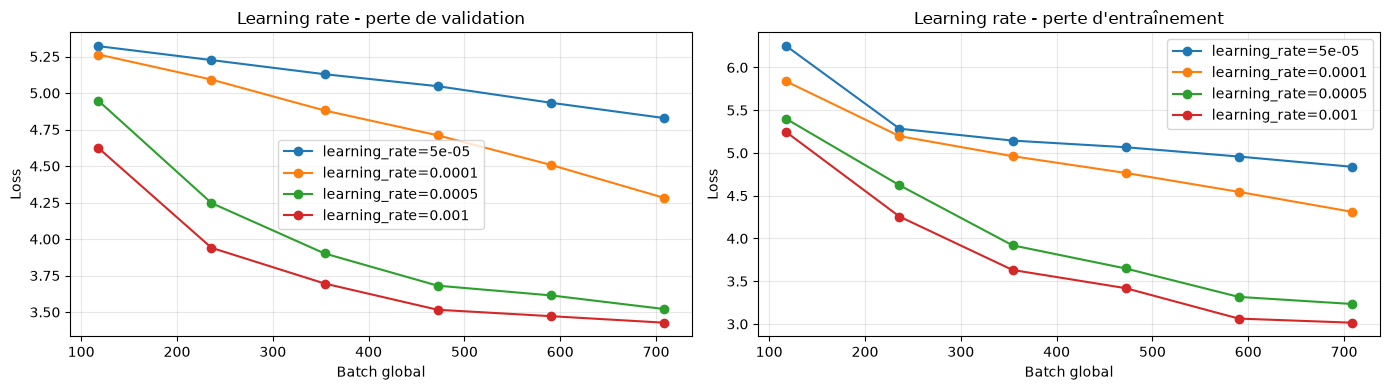

Learning rate retenu : 0.001


In [27]:
learning_rates = [5e-5, 1e-4, 5e-4, 1e-3]

lr_results = [run_experiment(lr, DROPOUT, 0.0, 0.0) for lr in learning_rates]
best_lr = show_experiments(lr_results, "learning_rate", "Learning rate")["learning_rate"]
print(f"Learning rate retenu : {best_lr}")

### Influence du dropout

lr=0.001 dropout=0.0 l1=0 l2=0 | époque 1/3:   0%|          | 0/237 [00:00<?, ?it/s]

/home/jxc/.venvs/data/lib/python3.12/site-packages/keras/src/backend/torch/rnn.py:887: UserWarning: RNN module weights are not part of single contiguous chunk of memory. This means they need to be compacted at every call, possibly greatly increasing memory usage. To compact weights again call flatten_parameters(). (Triggered internally at /pytorch/aten/src/ATen/native/cudnn/RNN.cpp:1479.)
  outputs, h_n = torch._VF.gru(


lr=0.001 dropout=0.0 l1=0 l2=0 | batch 118/711 | loss=5.2359 | val_loss=4.6295 | accuracy=0.2652 | 54 s depuis le début de l'époque
lr=0.001 dropout=0.0 l1=0 l2=0 | batch 236/711 | loss=4.3131 | val_loss=4.0195 | accuracy=0.3218 | 109 s depuis le début de l'époque
lr=0.001 dropout=0.0 l1=0 l2=0 | époque 1/3 | BLEU=0.0353 | 109 s


lr=0.001 dropout=0.0 l1=0 l2=0 | époque 2/3:   0%|          | 0/237 [00:00<?, ?it/s]

lr=0.001 dropout=0.0 l1=0 l2=0 | batch 354/711 | loss=3.6685 | val_loss=3.7048 | accuracy=0.3491 | 50 s depuis le début de l'époque
lr=0.001 dropout=0.0 l1=0 l2=0 | batch 472/711 | loss=3.4194 | val_loss=3.5152 | accuracy=0.3691 | 99 s depuis le début de l'époque
lr=0.001 dropout=0.0 l1=0 l2=0 | époque 2/3 | BLEU=0.0500 | 100 s


...

lr=0.001 dropout=0.5 l1=0 l2=0 | époque 2/3:   0%|          | 0/237 [00:00<?, ?it/s]

lr=0.001 dropout=0.5 l1=0 l2=0 | batch 354/711 | loss=3.6731 | val_loss=3.7009 | accuracy=0.3486 | 51 s depuis le début de l'époque
lr=0.001 dropout=0.5 l1=0 l2=0 | batch 472/711 | loss=3.4718 | val_loss=3.5424 | accuracy=0.3644 | 104 s depuis le début de l'époque
lr=0.001 dropout=0.5 l1=0 l2=0 | époque 2/3 | BLEU=0.0546 | 104 s


lr=0.001 dropout=0.5 l1=0 l2=0 | époque 3/3:   0%|          | 0/237 [00:00<?, ?it/s]

lr=0.001 dropout=0.5 l1=0 l2=0 | batch 590/711 | loss=3.1416 | val_loss=3.5140 | accuracy=0.3693 | 50 s depuis le début de l'époque
lr=0.001 dropout=0.5 l1=0 l2=0 | batch 708/711 | loss=3.0983 | val_loss=3.4495 | accuracy=0.3743 | 105 s depuis le début de l'époque
lr=0.001 dropout=0.5 l1=0 l2=0 | époque 3/3 | BLEU=0.0376 | 106 s
==> lr=0.001 dropout=0.5 l1=0 l2=0 | val_loss=3.4495 | écart=+0.3512 | meilleur batch=708 | 6.2 min



,learning_rate,dropout,l1,l2,best_step,train_loss,validation_loss,generalization_gap,final_bleu,duration_min
0,0.001,0.3,0.0,0.0,708,3.015386,3.427523,0.412137,0.045664,7.990598
1,0.001,0.0,0.0,0.0,708,2.972258,3.428523,0.456264,0.040370,5.248233
2,0.001,0.2,0.0,0.0,708,2.983116,3.432779,0.449663,0.045372,5.455816
3,0.001,0.5,0.0,0.0,708,3.098308,3.449524,0.351216,0.037559,6.245141


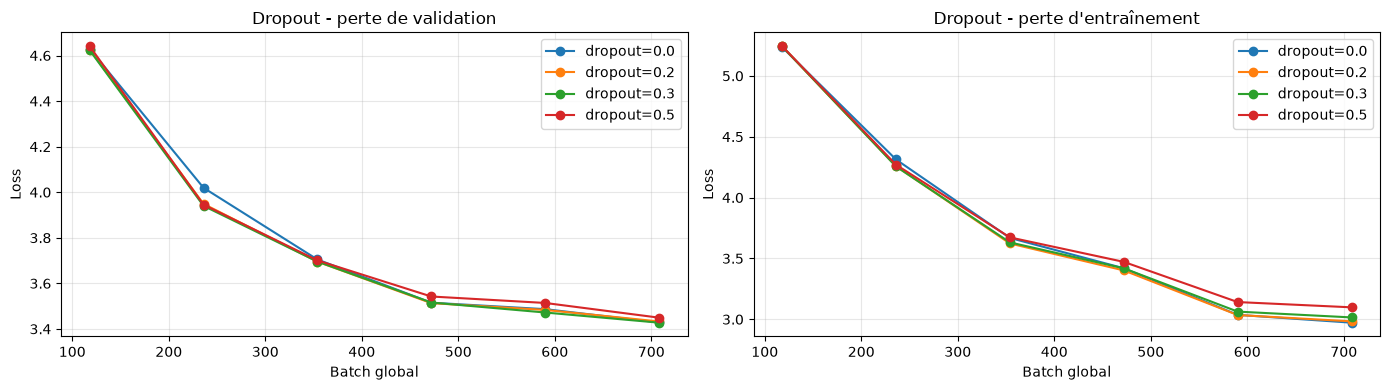

Dropout retenu : 0.3


In [28]:
dropouts = [0.0, 0.2, 0.3, 0.5]

dropout_results = [run_experiment(best_lr, dropout, 0.0, 0.0) for dropout in dropouts]
best_dropout = show_experiments(dropout_results, "dropout", "Dropout")["dropout"]
print(f"Dropout retenu : {best_dropout}")

### Influence de l'elastic net
Le livrable 1 utilisait `L1L2(l1=1e-4, l2=1e-4)` sur ses couches denses. On teste cette valeur, une plus faible et une plus forte, et la configuration sans régularisation comme référence.

lr=0.001 dropout=0.3 l1=0 l2=0 | époque 1/3:   0%|          | 0/237 [00:00<?, ?it/s]

/home/jxc/.venvs/data/lib/python3.12/site-packages/keras/src/backend/torch/rnn.py:887: UserWarning: RNN module weights are not part of single contiguous chunk of memory. This means they need to be compacted at every call, possibly greatly increasing memory usage. To compact weights again call flatten_parameters(). (Triggered internally at /pytorch/aten/src/ATen/native/cudnn/RNN.cpp:1479.)
  outputs, h_n = torch._VF.gru(


lr=0.001 dropout=0.3 l1=0 l2=0 | batch 118/711 | loss=5.2421 | val_loss=4.6235 | accuracy=0.2689 | 53 s depuis le début de l'époque
lr=0.001 dropout=0.3 l1=0 l2=0 | batch 236/711 | loss=4.2557 | val_loss=3.9402 | accuracy=0.3261 | 102 s depuis le début de l'époque
lr=0.001 dropout=0.3 l1=0 l2=0 | époque 1/3 | BLEU=0.0374 | 103 s


lr=0.001 dropout=0.3 l1=0 l2=0 | époque 2/3:   0%|          | 0/237 [00:00<?, ?it/s]

lr=0.001 dropout=0.3 l1=0 l2=0 | batch 354/711 | loss=3.6318 | val_loss=3.6957 | accuracy=0.3496 | 47 s depuis le début de l'époque
lr=0.001 dropout=0.3 l1=0 l2=0 | batch 472/711 | loss=3.4190 | val_loss=3.5160 | accuracy=0.3665 | 98 s depuis le début de l'époque
lr=0.001 dropout=0.3 l1=0 l2=0 | époque 2/3 | BLEU=0.0465 | 99 s


...

lr=0.001 dropout=0.3 l1=0.001 l2=0.001 | époque 2/3:   0%|          | 0/237 [00:00<?, ?it/s]

lr=0.001 dropout=0.3 l1=0.001 l2=0.001 | batch 354/711 | loss=4.5675 | val_loss=4.4741 | accuracy=0.2848 | 48 s depuis le début de l'époque
lr=0.001 dropout=0.3 l1=0.001 l2=0.001 | batch 472/711 | loss=4.4200 | val_loss=4.3793 | accuracy=0.2972 | 95 s depuis le début de l'époque
lr=0.001 dropout=0.3 l1=0.001 l2=0.001 | époque 2/3 | BLEU=0.0281 | 96 s


lr=0.001 dropout=0.3 l1=0.001 l2=0.001 | époque 3/3:   0%|          | 0/237 [00:00<?, ?it/s]

lr=0.001 dropout=0.3 l1=0.001 l2=0.001 | batch 590/711 | loss=4.3125 | val_loss=4.3222 | accuracy=0.3041 | 50 s depuis le début de l'époque
lr=0.001 dropout=0.3 l1=0.001 l2=0.001 | batch 708/711 | loss=4.2614 | val_loss=4.2677 | accuracy=0.3070 | 97 s depuis le début de l'époque
lr=0.001 dropout=0.3 l1=0.001 l2=0.001 | époque 3/3 | BLEU=0.0289 | 98 s
==> lr=0.001 dropout=0.3 l1=0.001 l2=0.001 | val_loss=4.2677 | écart=+0.0063 | meilleur batch=708 | 4.9 min



,learning_rate,dropout,l1,l2,best_step,train_loss,validation_loss,generalization_gap,final_bleu,duration_min
0,0.001,0.3,0.00001,0.00001,708,3.134823,3.402562,0.267740,0.047823,4.943683
1,0.001,0.3,0.00000,0.00000,708,3.015386,3.427523,0.412137,0.045664,5.004575
2,0.001,0.3,0.00010,0.00010,708,3.762113,3.802531,0.040418,0.030356,4.899646
3,0.001,0.3,0.00100,0.00100,708,4.261421,4.267734,0.006312,0.028947,4.874152


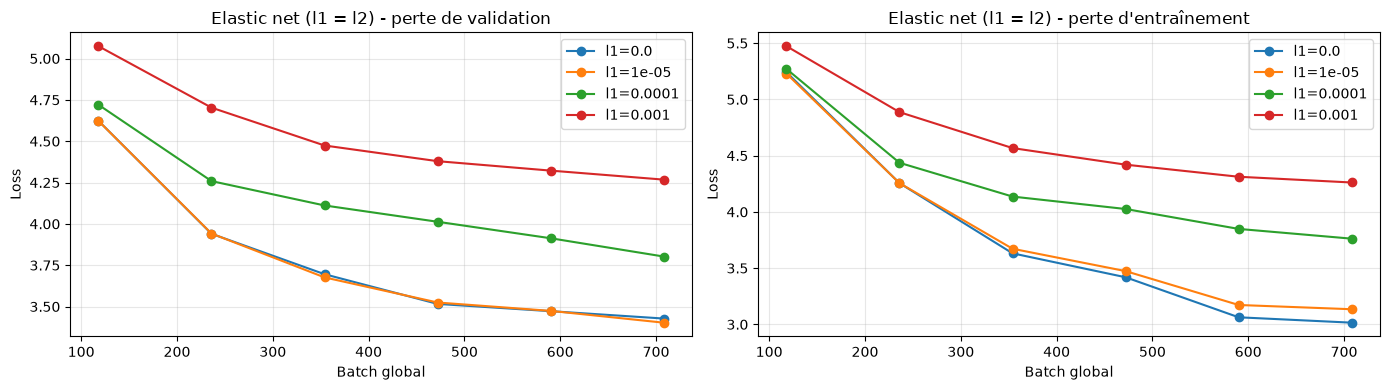

Elastic net retenu : l1 = l2 = 1e-05


In [29]:
elastic_values = [0.0, 1e-5, 1e-4, 1e-3]  # même valeur pour l1 et l2

elastic_results = [run_experiment(best_lr, best_dropout, value, value) for value in elastic_values]
best_elastic = show_experiments(elastic_results, "l1", "Elastic net (l1 = l2)")
print(f"Elastic net retenu : l1 = l2 = {best_elastic['l1']}")

In [30]:
# Récapitulatif : meilleure configuration trouvée
print(f"Learning rate : {best_lr}")
print(f"Dropout       : {best_dropout}")
print(f"Elastic net   : l1 = {best_elastic['l1']}, l2 = {best_elastic['l2']}")
print(f"Perte de validation : {best_elastic['validation_loss']:.4f} (batch {best_elastic['best_step']}, BLEU {best_elastic['final_bleu']:.4f})")
print(f"Écart validation - entraînement : {best_elastic['generalization_gap']:+.4f}")

Learning rate : 0.001
Dropout       : 0.3
Elastic net   : l1 = 1e-05, l2 = 1e-05
Perte de validation : 3.4026 (batch 708, BLEU 0.0478)
Écart validation - entraînement : +0.2677
